<a href="https://colab.research.google.com/github/venkat-prasath/uk-retail-sales-customer-analytics/blob/main/notebooks/01_retail_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import requests
import zipfile
import io

# Download the dataset ZIP file
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
response.raise_for_status()

# Open the ZIP file in memory
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Files found:", z.namelist())

    # Find the Excel file inside the ZIP
    excel_file = next(
        name for name in z.namelist()
        if name.lower().endswith((".xlsx", ".xls"))
    )

    # Read the Excel file
    with z.open(excel_file) as f:
        df = pd.read_excel(f)

# Display the results
print("Dataset shape:", df.shape)
display(df.head())

Files found: ['Online Retail.xlsx']
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# 1. Inspect the dataset
print("Original rows:", len(df))
print("Original columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check invalid quantities and prices
print("\nNon-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())

# 5. Check invoice dates
print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Original rows: 541909
Original columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Non-positive quantities: 10624
Non-positive prices: 2517

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [4]:
# Make a working copy of the original dataset
retail = df.copy()

# Convert invoice dates to datetime
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"], errors="coerce"
)

# Remove duplicate records and rows missing essential fields
retail = retail.drop_duplicates()

retail = retail.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity",
            "UnitPrice", "InvoiceDate"]
)

# Remove invalid quantities and prices
retail = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

# Exclude cancelled invoices (invoice numbers beginning with C)
retail = retail[
    ~retail["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Calculate transaction-line revenue
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]

print("Original rows:", len(df))
print("Cleaned rows:", len(retail))
print("Rows removed:", len(df) - len(retail))

display(retail.head())

Original rows: 541909
Cleaned rows: 524878
Rows removed: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


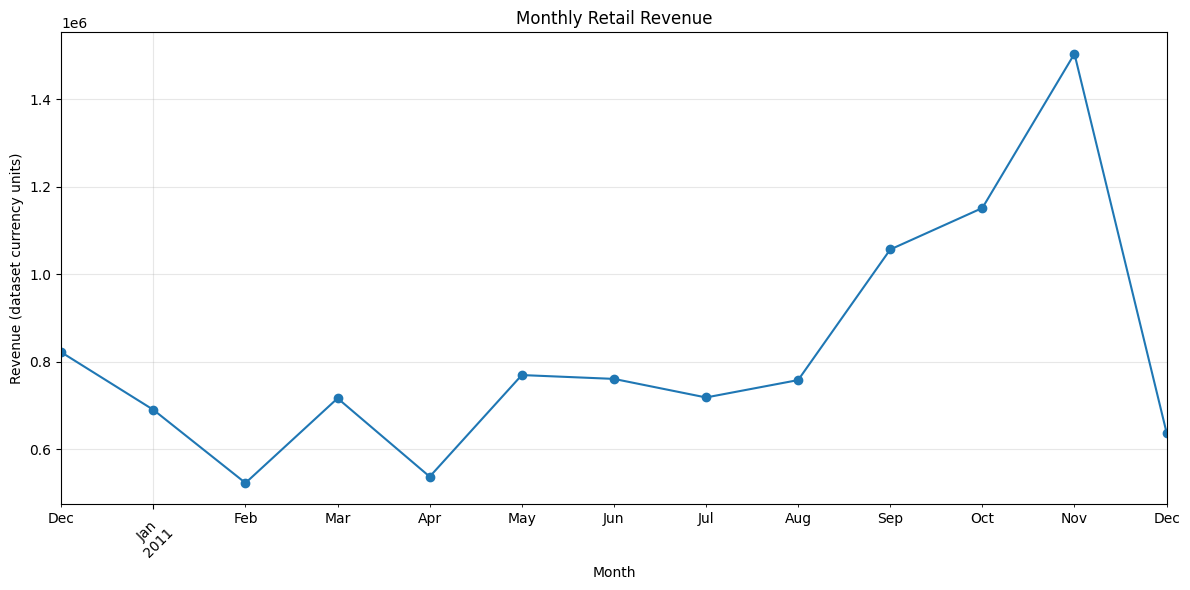

In [5]:
import matplotlib.pyplot as plt

# Summarise revenue by month
monthly_revenue = (
    retail.groupby(retail["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Plot monthly revenue
plt.figure(figsize=(12, 6))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency units)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

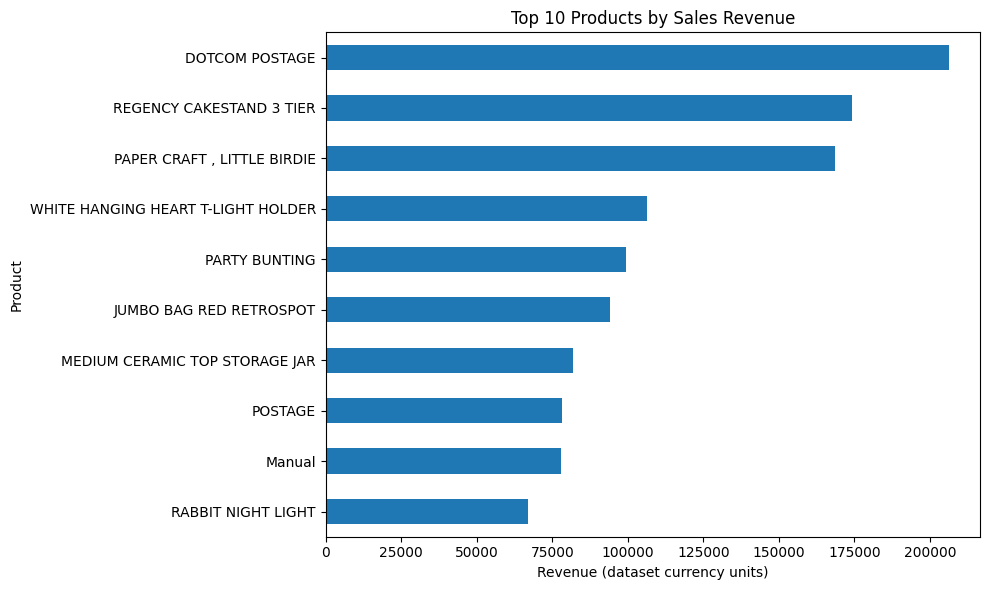

In [6]:
top_products = (
    retail.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue (dataset currency units)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()